# Mašinsko učenje – domaći zadatak 2
**Izbor modela polinomijalne regresije. Protočne transformacije u scikit-learn**

Podaci: $X$ – srednja godišnja količina padavina (mm), $Y$ – biljna biomasa (t/ha).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             root_mean_squared_error, r2_score)

np.set_printoptions(precision=4)
SEED = 42

## Zadatak 1

Skup sam proširila na $N = 100$ tako što sam kroz originalnih 10 tačaka provukla polinom 3. stepena (trend), generisala 90 novih vrednosti $X$ uniformno iz opsega 500–1550 mm i dodala normalan šum $\varepsilon \sim \mathcal{N}(0,\ 0{,}3^2)$ na vrednosti trenda. Originalnih 10 merenja je zadržano.

In [2]:
X0 = np.array([520, 610, 700, 820, 910, 1030, 1120, 1250, 1390, 1510])
Y0 = np.array([3.1, 3.8, 4.0, 5.1, 5.3, 6.0, 6.2, 5.9, 5.1, 4.1])

rng = np.random.default_rng(SEED)
trend = np.poly1d(np.polyfit(X0, Y0, 3))

X_new = np.round(rng.uniform(500, 1550, 90))
Y_new = np.round(trend(X_new) + rng.normal(0, 0.3, 90), 2)

df = pd.DataFrame({"X": np.r_[X0, X_new], "Y": np.r_[Y0, Y_new]})
df.to_csv("data.csv", index=False)
print(df.shape)
df.describe().round(2)

(100, 2)


,X,Y
count,100.00,100.00
mean,1016.18,5.07
std,290.19,0.90
min,508.00,3.00
25%,744.25,4.29
50%,997.00,5.34
75%,1264.00,5.81
max,1524.00,6.37


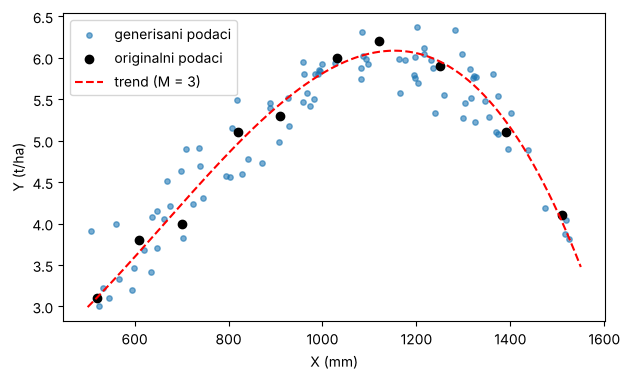

In [3]:
xs = np.linspace(500, 1550, 300)
plt.figure(figsize=(7, 4))
plt.scatter(X_new, Y_new, s=15, alpha=0.6, label="generisani podaci")
plt.scatter(X0, Y0, c="k", label="originalni podaci")
plt.plot(xs, trend(xs), "r--", label="trend (M = 3)")
plt.xlabel("X (mm)")
plt.ylabel("Y (t/ha)")
plt.legend()
plt.show()

## Zadatak 2

### 2.1 – `get_params`

Klasa je ista kao u prethodnom domaćem, samo sam dodala `get_params` i `set_params`. `GridSearchCV` preko njih čita i menja hiperparametre (`degree`, `alpha`), a `clone` pravi nove kopije modela za svaku podelu. `get_params` vraća rečnik sa parametrima iz konstruktora.

In [4]:
class PolynomialRegression(BaseEstimator, RegressorMixin):
    def __init__(self, degree=1, alpha=0.0):
        self.degree = degree
        self.alpha = alpha

    def get_params(self, deep=True):
        return {"degree": self.degree, "alpha": self.alpha}

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

    def _design_matrix(self, X):
        x = np.asarray(X, dtype=float).ravel()
        return np.vander(x, self.degree + 1, increasing=True)

    def fit(self, X, y):
        Phi = self._design_matrix(X)
        y = np.asarray(y, dtype=float).ravel()
        N, P = Phi.shape
        A = Phi.T @ Phi + N * self.alpha * np.eye(P)
        self.coef_ = np.linalg.solve(A, Phi.T @ y)
        return self

    def predict(self, X):
        return self._design_matrix(X) @ self.coef_

    def score(self, X, y):
        y = np.asarray(y, dtype=float).ravel()
        return np.mean((y - self.predict(X)) ** 2)  # MSE


m = PolynomialRegression(degree=3, alpha=0.01)
print(m.get_params())
print(m.set_params(degree=5).get_params())

{'degree': 3, 'alpha': 0.01}
{'degree': 5, 'alpha': 0.01}


Pošto moj `score` vraća MSE (manje je bolje), a `GridSearchCV` uvek bira **najveći** skor, u pretrazi zadajem `scoring="neg_mean_squared_error"` (negativan MSE).

### 2.2 – Pipeline

Pipeline ima dva koraka: standardizaciju $x \to (x - \bar{x})/s_x$ i polinomijalnu regresiju. Standardizacija rešava problem loše uslovljenosti iz prvog domaćeg (umesto $x^9 \approx 10^{28}$ sada su stepeni reda veličine 1), a kazna $\lambda\lVert\mathbf{w}\rVert^2$ podjednako deluje na sve koeficijente. `StandardScaler` se u okviru pipeline-a fituje samo na podacima za obuku, pa nema curenja informacija iz test skupa.

In [5]:
X, y = df[["X"]], df["Y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialRegression()),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('poly', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,degree,1
,alpha,0.0


### 2.3 i 2.4 – GridSearchCV sa $k$-fold unakrsnom validacijom

Skup sam podelila na obuku (80 tačaka) i test (20 tačaka). Na skupu za obuku `GridSearchCV` radi 10-fold unakrsnu validaciju za svaku kombinaciju $M$ i $\lambda$ (ukupno $10 \times 7 = 70$ kombinacija), bira onu sa najmanjim srednjim MSE na validacionim podskupovima i ponovo je fituje na celom skupu za obuku. Test skup se koristi tek na kraju. Parametrima unutar pipeline-a se pristupa sa `ime_koraka__parametar`.

In [6]:
param_grid = {
    "poly__degree": list(range(1, 11)),
    "poly__alpha": [0, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10],
}
kfold = KFold(n_splits=10, shuffle=True, random_state=SEED)

grid = GridSearchCV(pipe, param_grid, cv=kfold, scoring="neg_mean_squared_error")
grid.fit(X_train, y_train)

best = grid.best_estimator_
print("najbolji parametri:", grid.best_params_)
print("CV MSE:", -grid.best_score_)
print("koeficijenti:", best.named_steps["poly"].coef_)
print("test MSE:", mean_squared_error(y_test, best.predict(X_test)))

najbolji parametri: {'poly__alpha': 0.0001, 'poly__degree': 3}
CV MSE: 0.07897944837446709
koeficijenti: [ 5.7742  0.8041 -0.7516 -0.2066]
test MSE: 0.08944102375020269


In [7]:
res = pd.DataFrame(grid.cv_results_)
table = res.pivot(index="param_poly__degree", columns="param_poly__alpha",
                  values="mean_test_score")
(-table).round(4)

param_poly__alpha,0.0000,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000
param_poly__degree,,,,,,,
1,0.6050,0.6050,0.6049,0.6067,0.8095,6.9782,21.7356
2,0.1107,0.1107,0.1108,0.1192,0.6382,6.6680,19.4754
3,0.0790,0.0790,0.0790,0.0874,0.6179,6.6914,19.4235
4,0.0823,0.0823,0.0825,0.0968,0.5764,6.9210,17.8827
5,0.0865,0.0865,0.0863,0.0988,0.5664,6.8495,17.8928
6,0.0926,0.0924,0.0911,0.0969,0.6000,6.4415,18.3322
7,0.1006,0.1002,0.0977,0.1023,0.6051,6.4056,18.2436
8,0.0882,0.0885,0.0920,0.1035,0.5677,6.5593,17.9063
9,0.0952,0.0944,0.0969,0.1106,0.5745,6.5413,17.8266


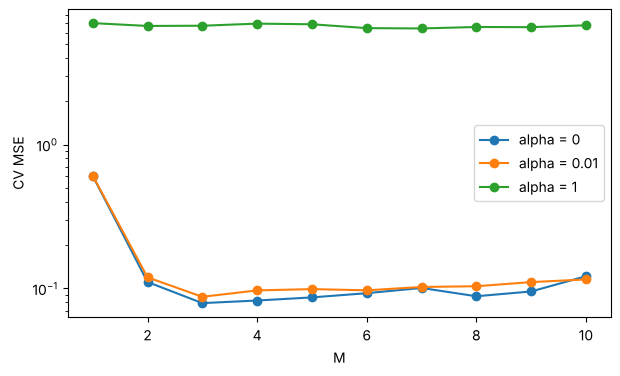

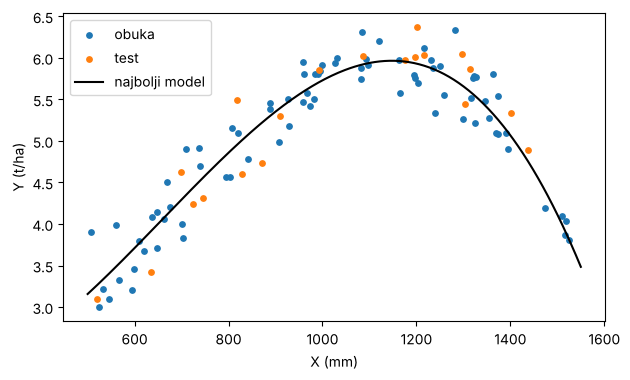

In [8]:
plt.figure(figsize=(7, 4))
for a in [0, 1e-2, 1]:
    r = res[res["param_poly__alpha"] == a]
    plt.plot(r["param_poly__degree"], -r["mean_test_score"], "o-", label=f"alpha = {a}")
plt.yscale("log")
plt.xlabel("M")
plt.ylabel("CV MSE")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(X_train, y_train, s=15, label="obuka")
plt.scatter(X_test, y_test, s=15, c="tab:orange", label="test")
plt.plot(xs, best.predict(pd.DataFrame({"X": xs})), "k", label="najbolji model")
plt.xlabel("X (mm)")
plt.ylabel("Y (t/ha)")
plt.legend()
plt.show()

**Ugnježdena unakrsna validacija.** Jedna podela na obuku i test zavisi od toga koje su tačke slučajno završile u testu. Zato sam još ocenila ceo postupak (pretraga + fit) ugnježdenom unakrsnom validacijom: spoljašnja 5-fold petlja deli podatke na obuku i test, a unutrašnja (`GridSearchCV`, 10-fold) bira hiperparametre samo na delu za obuku.

In [9]:
outer = KFold(n_splits=5, shuffle=True, random_state=0)
nested = cross_val_score(grid, X, y, cv=outer, scoring="neg_mean_squared_error")
print("MSE po spoljašnjim podelama:", (-nested).round(4))
print(f"nested CV MSE = {-nested.mean():.4f} ± {nested.std():.4f}")

MSE po spoljašnjim podelama: [0.0538 0.0853 0.1016 0.1059 0.0654]
nested CV MSE = 0.0824 ± 0.0202


Najbolji model je $M = 3$ sa $\lambda = 10^{-4}$ (CV MSE ≈ 0,079, test MSE ≈ 0,089), što odgovara trendu kojim sam generisala podatke. Za veće $M$ greška na validaciji uglavnom raste (overfitting), a za $M = 1$ je mnogo veća (underfitting). Mala regularizacija ($\lambda \le 10^{-3}$) daje skoro iste rezultate kao $\lambda = 0$, a malo pomaže samo za velike $M$ (npr. $M = 10$: 0,122 → 0,098). Za $\lambda \ge 0{,}1$ greška naglo raste jer se kažnjava i slobodni član $w_0$, pa se predikcija vuče ka nuli umesto ka srednjoj vrednosti biomase (≈ 5 t/ha). Ugnježdeni CV MSE (≈ 0,082 ± 0,020) je blizu varijanse šuma ($0{,}3^2 = 0{,}09$), što znači da model hvata trend, a ostatak greške je šum.

## Zadatak 3

| Metrika | Formula | Prednosti | Mane |
|---|---|---|---|
| MAE | $\frac{1}{N}\sum \lvert y_i - \hat y_i \rvert$ | ista jedinica kao $Y$ (t/ha), lako se tumači; otporna na outlier-e | nije diferencijabilna u 0; ne kažnjava jače velike greške |
| MSE | $\frac{1}{N}\sum (y_i - \hat y_i)^2$ | diferencijabilna, odgovara kriterijumu najmanjih kvadrata (i normalnom šumu) | jedinica je (t/ha)², teže se tumači; osetljiva na outlier-e |
| RMSE | $\sqrt{\mathrm{MSE}}$ | ista jedinica kao $Y$; kao i MSE jače kažnjava velike greške | osetljiva na outlier-e; uvek je $\mathrm{RMSE} \ge \mathrm{MAE}$ |
| $R^2$ | $1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$ | bez jedinice, pa se mogu porediti modeli na različitim podacima; 1 je savršen model, 0 je model koji uvek predviđa $\bar y$ | ne govori koliko je greška velika u jedinicama; zavisi od varijanse $Y$ u uzorku; na test skupu može biti negativan |

- **MAE** koristim kad podaci imaju outlier-e ili kad su sve greške podjednako bitne.
- **MSE** je pogodna za optimizaciju i poređenje modela (zato se koristi u `GridSearchCV`).
- **RMSE** je dobra za izveštavanje jer je u jedinicama $Y$, a velike greške su posebno nepoželjne.
- **$R^2$** je dobar za opis koliko varijanse model objašnjava, ali ga je dobro uvek dati uz neku metriku greške.

U scikit-learn su ovo funkcije `mean_absolute_error`, `mean_squared_error`, `root_mean_squared_error` i `r2_score`. Za `GridSearchCV` se koriste kao `scoring="neg_mean_absolute_error"`, `"neg_mean_squared_error"`, `"neg_root_mean_squared_error"` i `"r2"` (greške su negativne jer `GridSearchCV` maksimizuje skor). Metrike za najbolji model na test skupu:

In [10]:
y_pred = best.predict(X_test)
pd.Series({
    "MAE": mean_absolute_error(y_test, y_pred),
    "MSE": mean_squared_error(y_test, y_pred),
    "RMSE": root_mean_squared_error(y_test, y_pred),
    "R2": r2_score(y_test, y_pred),
}).round(4)

MAE     0.2571
MSE     0.0894
RMSE    0.2991
R2      0.8885
dtype: float64

Prosečna greška predikcije je oko 0,26 t/ha (MAE), RMSE je 0,30 t/ha, a model objašnjava oko 89% varijanse biomase ($R^2 \approx 0{,}89$).

## Zadatak 4

`StratifiedKFold` radi samo sa klasama, pa sam napravila sopstveni splitter: vrednosti $Y$ se podele u intervale po kvantilima (npr. 3 intervala: niske, srednje i visoke vrednosti biomase), pa se ti intervali koriste kao klase za `StratifiedKFold`. Tako svaki fold ima sličnu raspodelu biomase kao ceo skup. Klasa ima metode `split` i `get_n_splits`, pa može da se prosledi kao `cv` u `GridSearchCV`. Pošto `GridSearchCV` u `split` prosleđuje `y`, intervali se uvek računaju samo na podacima koje splitter dobije.

In [11]:
class StratifiedKFoldReg:
    def __init__(self, n_splits=10, n_bins=3, shuffle=True, random_state=None):
        self.n_splits = n_splits
        self.n_bins = n_bins
        self.shuffle = shuffle
        self.random_state = random_state

    def split(self, X, y, groups=None):
        y_bins = pd.qcut(np.asarray(y), q=self.n_bins, labels=False, duplicates="drop")
        skf = StratifiedKFold(self.n_splits, shuffle=self.shuffle,
                              random_state=self.random_state)
        return skf.split(X, y_bins)

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits

Provera: udeo niskih, srednjih i visokih vrednosti u validacionim podskupovima (za KFold i za stratifikovanu varijantu):

In [12]:
bins = pd.qcut(y_train, 3, labels=["niske", "srednje", "visoke"])

def fold_shares(cv):
    return pd.DataFrame([bins.iloc[val].value_counts(normalize=True)
                         for _, val in cv.split(X_train, y_train)]).round(2)

skf_reg = StratifiedKFoldReg(n_splits=10, n_bins=3, random_state=SEED)
print("KFold:\n", fold_shares(kfold).describe().loc[["min", "max"]])
print("\nStratifikovani:\n", fold_shares(skf_reg).describe().loc[["min", "max"]])

KFold:
 Y    srednje  visoke  niske
min     0.00    0.12   0.12
max     0.75    0.75   0.62

Stratifikovani:
 Y    srednje  visoke  niske
min     0.25    0.25   0.25
max     0.38    0.38   0.38


In [13]:
grid_strat = GridSearchCV(pipe, param_grid, cv=skf_reg, scoring="neg_mean_squared_error")
grid_strat.fit(X_train, y_train)

for name, g in [("KFold", grid), ("Stratifikovani", grid_strat)]:
    i = g.best_index_
    print(f"{name:15s} {g.best_params_}  CV MSE = {-g.best_score_:.4f} "
          f"(std po foldovima {g.cv_results_['std_test_score'][i]:.4f})  "
          f"test MSE = {mean_squared_error(y_test, g.predict(X_test)):.4f}")

KFold           {'poly__alpha': 0.0001, 'poly__degree': 3}  CV MSE = 0.0790 (std po foldovima 0.0288)  test MSE = 0.0894
Stratifikovani  {'poly__alpha': 0.001, 'poly__degree': 3}  CV MSE = 0.0788 (std po foldovima 0.0266)  test MSE = 0.0903


Sa stratifikacijom je udeo svake grupe u foldovima između 25% i 38%, dok kod običnog `KFold` neki foldovi nemaju nijednu srednju vrednost, a neki imaju 75% visokih. Izabran je isti stepen ($M = 3$), a CV i test greška su skoro iste, uz nešto manje rasipanje greške po foldovima (0,027 umesto 0,029). Razlika je mala jer je skup relativno ravnomeran, a 80 tačaka je dovoljno da i slučajne podele budu reprezentativne. Stratifikacija ima veći značaj kod malih skupova i kod asimetrične raspodele $Y$ (npr. malo tačaka sa ekstremnim vrednostima), jer tada slučajan fold može da ostane bez takvih vrednosti, pa je procena greške nestabilnija.